# Section 1: Data Selection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

pregnancy = pd.read_csv("..\\data\\Pregnancy.csv")
pregnancy["Risk Level"] = pregnancy["Risk Level"].map({
    "Low": 0,
    "High": 1
})

### Question 1

**Based on the Data Understanding analysis, which columns had the strongest relationship with Risk Level? List them in order of relationship strength.**

- Preexisting Diabetes => 0.68
- Mental Health => 0.63
- BS => 0.59
- Previous Complications => 0.54
- BMI => 0.52
- Heart Rate => 0.48
- Gestational Diabetes => 0.44
- Diastolic => 0.33
- Systolic BP => 0.29
- Body Temp => 0.21
- Age => 0.19

### Question 2

**Complete the following table:**

| Feature | Business Importance | Data Importance |
|---|---|---|

| Feature | Business Importance | Data Importance |
|---|---|---|
| Preexisting Diabetes | High | High (0.69) |
| Mental Health | High | High (0.64) |
| Blood Sugar | High | High (0.59) |
| Previous Complications | High | High (0.54) |
| BMI | High | High (0.52) |
| Heart Rate | Medium | Medium (0.48) |
| Gestational Diabetes | High | High(Maby Data Leakage) |
| Diastolic BP | High | Medium (0.33) |
| Systolic BP | High | Medium (0.29) |
| Body Temp | Low | Low (0.21) |
| Age | High | Low (0.20) |

### Question 3

**Identify at least three features that are not useful for modeling or carry risk.**

- Heart Rate
- Boy Temp
- Age => Convert to grouping

### Question 4

**Build a new version of the dataset containing only the selected features (`selected_df`), and compare the number of features before/after.**

In [2]:
selected_df = pregnancy.copy()
selected_df = selected_df.drop(columns=["Body Temp"])

print(f"Before: {pregnancy.shape[1]}")
print(f"After: {selected_df.shape[1]}")

Before: 12
After: 11


---

# Section 2: Data Cleaning

### Question 5

**Re-check missing values in `selected_df`.**

In [3]:
for column in selected_df.columns:
    missing_value = selected_df[column].isna().sum()
    print(f"{column} => {missing_value} null")

Age => 0 null
Systolic BP => 5 null
Diastolic => 4 null
BS => 2 null
BMI => 18 null
Previous Complications => 2 null
Preexisting Diabetes => 2 null
Gestational Diabetes => 0 null
Mental Health => 0 null
Heart Rate => 2 null
Risk Level => 18 null


### Question 6

**Propose three methods for handling missing values (with special attention to BMI, whose distribution differs between the two risk groups, and to Risk Level, for which imputing the target is not recommended).**

- Missing qualitative data can be replaced using the random forest algorithm.
- Imputing numerical data using the mean or median ignores the relationships between the features and the target variable.
- Removing records that contain missing data.

### Question 7

**Implement one of the methods.**

In [4]:
selected_df = selected_df.dropna(subset = ["Risk Level"]).reset_index(drop = True)

for level in selected_df["Risk Level"].unique():
    median_value = selected_df[selected_df["Risk Level"] == level]["BMI"].median()
    state = (selected_df["Risk Level"] == level) & (selected_df["BMI"].isna())
    selected_df.loc[state, "BMI"] = median_value
    
numeric_missing = [
    "Systolic BP", "Diastolic", "BS",
    "Previous Complications", "Preexisting Diabetes",
    "Heart Rate"
]

for column in numeric_missing:
    median_value = selected_df[column].median()
    selected_df[column] = selected_df[column].fillna(median_value)
    
for column in selected_df.columns:
    missing_value = selected_df[column].isna().sum()
    print(f"{column} => {missing_value} null")

Age => 0 null
Systolic BP => 0 null
Diastolic => 0 null
BS => 0 null
BMI => 0 null
Previous Complications => 0 null
Preexisting Diabetes => 0 null
Gestational Diabetes => 0 null
Mental Health => 0 null
Heart Rate => 0 null
Risk Level => 0 null


### Question 8

**Identify and remove duplicate records**

In [5]:
before_counting = selected_df.duplicated().sum()

selected_df = selected_df.drop_duplicates().reset_index(drop = True)
after_counting = selected_df.duplicated().sum()

print(f"Number of duplicate records entries before removel:{before_counting}")
print(f"Number of duplicate records entries after removel:{after_counting}")


Number of duplicate records entries before removel:19
Number of duplicate records entries after removel:0


### Question 9

**Identify and handle medically implausible values (BMI=0, implausible age, physiologically impossible values) — remove or replace with clinical justification.**

In [6]:
selected_df = selected_df[
    (selected_df['BMI'] != 0) 
    & (selected_df['Diastolic'] < selected_df['Systolic BP']) 
    & (selected_df['Age'] >= 12)
]

### Question 10

**Using IQR, identify outliers for each numeric feature and report them.**

In [7]:
numeric_features = ["Age", "Systolic BP", "Diastolic", "BS", "Body Temp", "BMI", "Heart Rate"]

for column in numeric_features:
    q1 = pregnancy[column].quantile(0.25)
    q3 = pregnancy[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = pregnancy[
        (pregnancy[column] < lower_bound)
        | (pregnancy[column] > upper_bound)
    ]
    print(f"{column} => {len(outliers)} outliers.")
    

Age => 73 outliers.
Systolic BP => 8 outliers.
Diastolic => 2 outliers.
BS => 181 outliers.
Body Temp => 175 outliers.
BMI => 37 outliers.
Heart Rate => 0 outliers.


### Question 11

**Propose three strategies for handling outliers.**
- We can remove records that are outliers from our dataset.

- Consider data that is smaller than lower bound as lower bound itself, and data that is larger than upper bound as upper bound itself to remove outliers.

- We can replace outliers with the mean, median, or mode.

### Question 12

**Implement the chosen strategy .**

It is better not to make any changes, as our outlier data indicate a very high-risk pregnancy.

---

# Section 3: Data Construction (Feature Engineering)

**Question 13**

Bin Age based on pregnancy risk: Teen (under 18), Normal Reproductive Age (18–35), Advanced Maternal Age (36+). Column: `age_group`

In [8]:
def age_group(age):
    if age < 18:
        return "Teen"
    elif age <= 35:
        return "Normal"
    else:
        return "Advanced"

selected_df["age_group"] = selected_df["Age"].apply(age_group)

selected_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group
0,22,90.0,60.0,9.0,18.0,1.0,1.0,0,1,80.0,1.0,Normal
1,22,110.0,70.0,7.1,20.4,0.0,0.0,0,0,74.0,0.0,Normal
2,27,110.0,70.0,7.5,23.0,1.0,0.0,0,0,72.0,0.0,Normal
3,20,100.0,70.0,7.2,21.2,0.0,0.0,0,0,74.0,0.0,Normal
4,20,90.0,60.0,7.5,19.7,0.0,0.0,0,0,74.0,0.0,Normal


### Question 14

**For BS, create risk levels based on the actual thresholds found in the data (Normal <6, Borderline 6–7.5, Elevated 7.5–9, High 9+). Column: `bs_risk_level`**

In [9]:
def bs_risk(bs):
    if bs < 6:
        return "Normal"
    elif bs < 7.5:
        return "Borderline"
    elif bs < 9:
        return "Elevated"
    else:
        return "High"

selected_df["bs_risk_level"] = selected_df["BS"].apply(bs_risk)

**Question 15**

**For Systolic/Diastolic BP, create a blood-pressure-level feature based on clinical thresholds for pregnancy hypertension (Systolic ≥ 140 or Diastolic ≥ 90). Column: `bp_level`**

In [10]:
def bp_risk(systolic, diastolic):
    if systolic >= 140 or diastolic >= 90:
        return "Hypertensive"
    else:
        return "Normal"

def apply_bp_risk(row):
    return bp_risk(row["Systolic BP"], row["Diastolic"])

selected_df["bp_level"] = selected_df.apply(apply_bp_risk, axis=1)

selected_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group,bs_risk_level,bp_level
0,22,90.0,60.0,9.0,18.0,1.0,1.0,0,1,80.0,1.0,Normal,High,Normal
1,22,110.0,70.0,7.1,20.4,0.0,0.0,0,0,74.0,0.0,Normal,Borderline,Normal
2,27,110.0,70.0,7.5,23.0,1.0,0.0,0,0,72.0,0.0,Normal,Elevated,Normal
3,20,100.0,70.0,7.2,21.2,0.0,0.0,0,0,74.0,0.0,Normal,Borderline,Normal
4,20,90.0,60.0,7.5,19.7,0.0,0.0,0,0,74.0,0.0,Normal,Elevated,Normal


### Question 16

**For BMI, create the standard clinical categories (Underweight/Normal/Overweight/Obese) Column: `bmi_category`.**

In [11]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 25:
        return "Normal"
    elif bmi < 30:
        return "Overweight"
    else:
        return "Obese"

selected_df["bmi_category"] = selected_df["BMI"].apply(bmi_category)

### Question 17

**Create a `risk_factor_count` feature (the sum of simultaneous risk factors for each patient) and show how the probability of High-risk changes as this number increases.**

In [12]:
selected_df["risk_factor_count"] = (
    (selected_df["bmi_category"] == "Obese").astype(int)
    + (selected_df["bs_risk_level"].isin(["Elevated", "High"])).astype(int)
    + (selected_df["bp_level"] == "Hypertensive").astype(int)
    + (selected_df["Gestational Diabetes"] == 1).astype(int)
    + (selected_df["Preexisting Diabetes"] == 1).astype(int)
    + (selected_df["Previous Complications"] == 1).astype(int)
    + (selected_df["age_group"] != "Normal").astype(int)
)
temp = sorted(selected_df["risk_factor_count"].unique())
for count in temp:
    state = selected_df[selected_df["risk_factor_count"] == count]
    probability = (state["Risk Level"] == 1).mean() * 100

    print(f"Risk factors = {count} | Patients = {len(state)} | High-risk probability = {probability.round(2)}%")

Risk factors = 0 | Patients = 425 | High-risk probability = 0.24%
Risk factors = 1 | Patients = 261 | High-risk probability = 19.16%
Risk factors = 2 | Patients = 171 | High-risk probability = 69.01%
Risk factors = 3 | Patients = 117 | High-risk probability = 95.73%
Risk factors = 4 | Patients = 122 | High-risk probability = 100.0%
Risk factors = 5 | Patients = 65 | High-risk probability = 100.0%
Risk factors = 6 | Patients = 5 | High-risk probability = 100.0%


### Question 18

**Design at least two additional new features (e.g., `is_hypertensive`, `pulse_pressure`).**

In [13]:
selected_df["is_hypertensive"] = (selected_df["bp_level"] == "Hypertensive")
selected_df["pulse_pressure"] = selected_df["Systolic BP"] - selected_df["Diastolic"]

---

# Section 4: Data Formatting

### Question 19
**Check the data type of all columns.**

We have a set of features that need to be converted into categories.

In [14]:
selected_df.dtypes

Age                         int64
Systolic BP               float64
Diastolic                 float64
BS                        float64
BMI                       float64
Previous Complications    float64
Preexisting Diabetes      float64
Gestational Diabetes        int64
Mental Health               int64
Heart Rate                float64
Risk Level                float64
age_group                     str
bs_risk_level                 str
bp_level                      str
bmi_category                  str
risk_factor_count           int64
is_hypertensive              bool
pulse_pressure            float64
dtype: object

### Question 20

**Apply the appropriate datatype and report its effect on memory usage.**

In [15]:
memory_before = selected_df.memory_usage(deep=True).sum()

categorical_features = [
    "Previous Complications", "Preexisting Diabetes", "Gestational Diabetes",
    "Mental Health", "Risk Level", "age_group",
    "bs_risk_level", "bp_level", "bmi_category"
]
for column in categorical_features:
    selected_df[column] = selected_df[column].astype("category")

selected_df["is_hypertensive"] = selected_df["is_hypertensive"].astype("bool")

memory_after = selected_df.memory_usage(deep=True).sum()

print(f"Memory before: {memory_before.round(2)} bytes")
print(f"Memory after : {memory_after.round(2)} bytes")

selected_df.dtypes

Memory before: 393641 bytes
Memory after : 96425 bytes


Age                          int64
Systolic BP                float64
Diastolic                  float64
BS                         float64
BMI                        float64
Previous Complications    category
Preexisting Diabetes      category
Gestational Diabetes      category
Mental Health             category
Heart Rate                 float64
Risk Level                category
age_group                 category
bs_risk_level             category
bp_level                  category
bmi_category              category
risk_factor_count            int64
is_hypertensive               bool
pulse_pressure             float64
dtype: object

### Question 21

**Check the Risk Level column and other text columns for consistency (High/high/HIGH) and standardize if necessary.**

This feature has been converted to 0 and 1.

---

# Section 5: Data Reduction

### Question 22

**Identify features with very low variance .**

In [16]:
numeric = ["Age", "Systolic BP", "Diastolic", "BS", "BMI", "Heart Rate", "pulse_pressure"]
variance = selected_df[numeric].var().sort_values()
variance

BS                  9.456722
BMI                14.653834
Heart Rate         52.570075
Age                85.173342
pulse_pressure    131.222111
Diastolic         205.424287
Systolic BP       352.077622
dtype: float64

### Question 23

**Identify features that are highly correlated with each other and display with a new Heatmap. (note: derived features like bs_risk_level naturally have high correlation with the raw BS feature).**

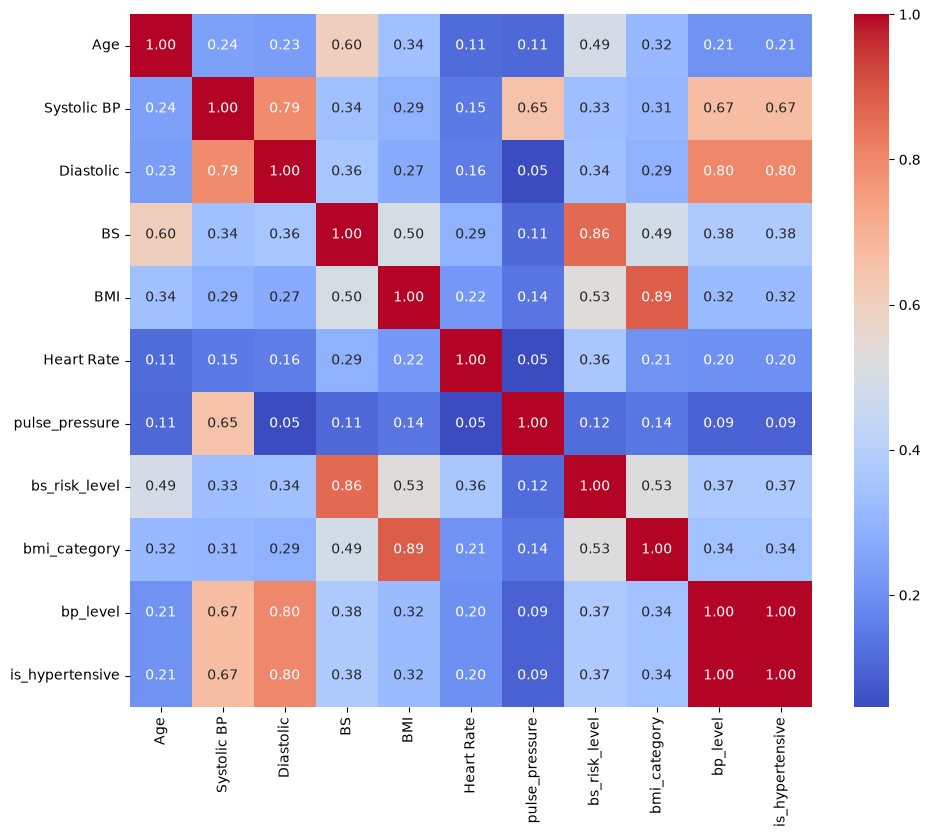

In [17]:
temp = selected_df.copy()

temp["bs_risk_level"] = temp["bs_risk_level"].map({
    "Normal": 0,
    "Borderline": 1,
    "Elevated": 2,
    "High": 3
})

temp["bmi_category"] = temp["bmi_category"].map({
    "Underweight": 0,
    "Normal": 1,
    "Overweight": 2,
    "Obese": 3
})

temp["bp_level"] = temp["bp_level"].map({
    "Normal": 0,
    "Hypertensive": 1
})

temp["is_hypertensive"] = temp["is_hypertensive"].astype(int)

correlation_column = [
    "Age", "Systolic BP", "Diastolic",
    "BS", "BMI", "Heart Rate", "pulse_pressure",
    "bs_risk_level","bmi_category", "bp_level", "is_hypertensive"
]

correlation = temp[correlation_column].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(
    data=correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()


### Question 24

**If two features have a correlation above 0.85, which one do you remove?**

We have three correlations higher than 0.85:
- BMI & bmi_category => (I’m keeping both so I can use them according to the chosen model.)
- BS & bs_risk_level => (I keep the raw blood sugar data and delete the categorized version, because more information can be extracted from the raw data.)
- bp_level & is_hypertensive => (Since blood pressure is either normal or dangerous, I am removing the bp_level field.)



### Question 25

**Document your final decision regarding Gestational Diabetes and BMI≥30: are they removed, kept, or kept with an explicit Leakage note?**

I am keeping both of them because they are significant in terms of clinical data, and anyone with these conditions faces a high-risk pregnancy.

### Question 26

**Build the final reduced version of the dataset (`reduced_df`).**

In [18]:
reduced_df = selected_df.drop(columns=["bs_risk_level", "bp_level"]).copy()
reduced_df.head()

,Age,Systolic BP,Diastolic,BS,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level,age_group,bmi_category,risk_factor_count,is_hypertensive,pulse_pressure
0,22,90.0,60.0,9.0,18.0,1.0,1.0,0,1,80.0,1.0,Normal,Underweight,3,False,30.0
1,22,110.0,70.0,7.1,20.4,0.0,0.0,0,0,74.0,0.0,Normal,Normal,0,False,40.0
2,27,110.0,70.0,7.5,23.0,1.0,0.0,0,0,72.0,0.0,Normal,Normal,2,False,40.0
3,20,100.0,70.0,7.2,21.2,0.0,0.0,0,0,74.0,0.0,Normal,Normal,0,False,30.0
4,20,90.0,60.0,7.5,19.7,0.0,0.0,0,0,74.0,0.0,Normal,Normal,1,False,30.0


---

# Section 6: Data Transformation (Scaling)

### Question 27

**Check whether the numeric features have very different scales.**

Yes, the numeric features live on very different scales.

In [19]:
check = reduced_df[numeric].agg(["min", "max", "mean", "std"]).T
check["range"] = check["max"] - check["min"]
check

,min,max,mean,std,range
Age,12.0,65.0,27.603774,9.228940,53.0
Systolic BP,70.0,200.0,116.880789,18.763732,130.0
Diastolic,40.0,140.0,77.280446,14.332630,100.0
BS,3.0,19.0,7.526055,3.075178,16.0
BMI,15.0,37.0,23.392624,3.828033,22.0
Heart Rate,58.0,92.0,75.883362,7.250522,34.0
pulse_pressure,10.0,100.0,39.600343,11.455222,90.0


### Question 28

**Compare which method (MinMax or Standardization) is more appropriate for this project, given the presence of real extreme values (not noise) in BS and BMI.**

Standardization is more appropriate here because minmax scaling would eliminate the BS and BMI data, which are not noise, whereas we did not completely remove the outliers because they are important.

In [20]:
numeric.append("risk_factor_count")
scaler = StandardScaler()
reduced_df[numeric] = scaler.fit_transform(reduced_df[numeric])

---

# Section 7: Dataset Validation

### Question 29

**Report a final data-quality checklist in a single table:**
- **Final shape of the dataset (rows/columns)** => (1166, 16)
- **Any remaining Nulls?** => 0
- **Any remaining duplicates?** => 0
- **Have medically implausible values been handled?** Yes
- **Is the format of all features appropriate?** Yes

In [21]:
reduced_df.shape

reduced_df.isnull().sum()

reduced_df.duplicated().sum()

np.int64(0)

### Question 30

**Is the data suitable for KNN, Logistic Regression, and Decision Tree/Random Forest? Explain separately for each.**

- `KNN:` It is suitable for this algorithm because we standardized the data and equalized the scales; the distances are now consistent, so the results for Manhattan and Euclidean distances are not surprising.
- `Logistic Regression:` Scaling is appropriate, but the grouped data require coding.
- `Decision Tree/Random Forest:` It works effectively even without scaling and is suitable; standardization is not necessary for this model.

### Question 31

**Save the final dataset:**
```python
pregnancy_prepared.csv
```

In [22]:
final = reduced_df.copy()
final.to_csv("../data/pregnancy_prepared.csv", index=False)
